# Health Insurance Fraud Detection (Model Deployment With Most features)

Import required Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import plotly.express as px
import scipy as scipy
import math
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegressionCV
from sklearn import metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, auc
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report

In [2]:
X = pd.read_csv("Training_data_X.csv")
y = pd.read_csv("Training_data_Y.csv")

In [3]:
X.shape, type(X), y.shape, type(y)

((5410, 299),
 pandas.core.frame.DataFrame,
 (5410, 1),
 pandas.core.frame.DataFrame)

In [4]:
X.head()

,InscClaimAmtReimbursed,DeductibleAmtPaid,RenalDiseaseIndicator,ChronicCond_Alzheimer,ChronicCond_Heartfailure,ChronicCond_KidneyDisease,ChronicCond_Cancer,ChronicCond_ObstrPulmonary,ChronicCond_Depression,ChronicCond_Diabetes,...,ClmCount_Provider_BeneID_ClmDiagnosisCode_9_ClmProcedureCode_3,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_1,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_2,ClmCount_Provider_BeneID_ClmDiagnosisCode_10_ClmProcedureCode_3,Gender_1,Race_2,Race_3,Race_5,Admitted?_1,Is_Alive?_1
0,104640,5340.0,8,15,19,17,5,10,9,21,...,0.0,0.0,0.0,0.0,9.0,4.0,0.0,0.0,5.0,0.0
1,605670,66286.0,29,56,80,64,10,41,54,100,...,0.0,3.0,1.0,0.0,54.0,24.0,0.0,1.0,62.0,1.0
2,52170,310.0,23,64,88,50,16,41,63,105,...,0.0,0.0,0.0,0.0,46.0,24.0,5.0,0.0,0.0,1.0
3,280910,3700.0,259,426,680,507,165,295,485,799,...,0.0,0.0,0.0,0.0,511.0,262.0,10.0,0.0,0.0,4.0
4,33710,3264.0,11,26,40,22,12,16,29,49,...,0.0,0.0,0.0,0.0,34.0,14.0,0.0,0.0,3.0,1.0


In [5]:
y.head()

,PotentialFraud
0,0
1,1
2,0
3,1
4,0


## **`Train Test Split` :: Creating TRAIN and VALIDATION sets.**

   * **`Reasoning`** :: These sets will be used for measurng the performance of ML Models.

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=39)

In [8]:
# Checking shape of each set
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((4328, 299), (1082, 299), (4328, 1), (1082, 1))

In [9]:
# Checking count of tgt labels in y_train
y_train.value_counts()

PotentialFraud
0                 3923
1                  405
dtype: int64

In [10]:
# Checking count of tgt labels in y_test
y_test.value_counts()

PotentialFraud
0                 981
1                 101
dtype: int64

In [11]:
pd.set_option('display.max_columns',30)
label_font_dict = {'family':'sans-serif','size':13.5,'color':'brown','style':'italic'}
title_font_dict = {'family':'sans-serif','size':16.5,'color':'Blue','style':'italic'}

# **`Standardizing TRAIN & TEST sets`** 
## **Bringing every feature into the same scale.**

In [12]:
from sklearn.preprocessing import RobustScaler

In [13]:
# Standardize the data (train and test)
robust_scaler = RobustScaler()
robust_scaler.fit(X_train)
X_train_std = robust_scaler.transform(X_train)
X_test_std = robust_scaler.transform(X_test)

In [14]:
def validate_model(clf, x_train, x_test, y_train, y_test):
    y_train_pred = pred_prob(clf, x_train)
    
    y_test_pred = pred_prob(clf, x_test)
    
    train_fpr, train_tpr, tr_thresholds = roc_curve(y_train, y_train_pred)
    test_fpr, test_tpr, te_thresholds = roc_curve(y_test, y_test_pred)
    
    train_auc = auc(train_fpr, train_tpr)
    print("Train AUC = {}".format(train_auc))
    test_auc = auc(test_fpr, test_tpr)
    print("Test AUC = {}".format(test_auc))
     
    draw_roc(train_fpr, train_tpr, test_fpr, test_tpr)
    
    best_t = find_best_threshold(tr_thresholds, train_fpr, train_tpr)
    
    train_prediction, test_prediction = draw_confusion_matrix(best_t, x_train, x_test, y_train, y_test, y_train_pred, y_test_pred)
    
    
    train_f1_score = f1_score(y_train, train_prediction)
    test_f1_score = f1_score(y_test, test_prediction)
    cr = classification_report(y_test, test_prediction)
    acc_scr = accuracy_score(y_test, test_prediction)

   
    return test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr

In [15]:
def pred_prob(clf, data): 
    
    y_pred = clf.predict_proba(data)[:,1]
    return y_pred

def draw_roc(train_fpr, train_tpr, test_fpr, test_tpr):
    
    train_auc = auc(train_fpr, train_tpr)
    test_auc = auc(test_fpr, test_tpr)
    with plt.style.context('seaborn-poster'):
      plt.plot(train_fpr, train_tpr, label="Train AUC ="+"{:.4f}".format(train_auc), color='blue')
      plt.plot(test_fpr, test_tpr, label="Test AUC ="+"{:.4f}".format(test_auc), color='red')
      plt.legend()
      plt.xlabel("False Positive Rate(FPR)", fontdict=label_font_dict)
      plt.ylabel("True Positive Rate(TPR)", fontdict=label_font_dict)
      plt.title("Area Under Curve", fontdict=title_font_dict)
      plt.grid(b=True, which='major', color='lightgrey', linestyle='--')
      plt.minorticks_on()
      plt.show()
    
def find_best_threshold(threshold, fpr, tpr):
    t = threshold[np.argmax(tpr * (1-fpr))]
    return t

def predict_with_best_t(proba, threshold):
    predictions = []
    for i in proba:
        if i>=threshold:
            predictions.append(1)
        else:
            predictions.append(0)
    return predictions

def draw_confusion_matrix(best_t, x_train, x_test, y_train, y_test, y_train_pred, y_test_pred):
    fig, ax = plt.subplots(1,2, figsize=(20,6))

    train_prediction = predict_with_best_t(y_train_pred, best_t)
    cm = confusion_matrix(y_train, train_prediction)
    with plt.style.context('seaborn'):
        sns.heatmap(cm, annot=True, fmt='d', ax=ax[0], cmap='viridis')
        ax[0].set_title('Train Dataset Confusion Matrix', fontdict=title_font_dict)
        ax[0].set_xlabel("Predicted Label", fontdict=label_font_dict)
        ax[0].set_ylabel("Actual Label", fontdict=label_font_dict)

    test_prediction = predict_with_best_t(y_test_pred, best_t)
    cm = confusion_matrix(y_test, test_prediction)
    with plt.style.context('seaborn'):
        sns.heatmap(cm, annot=True, fmt='d', ax=ax[1], cmap='summer')
        ax[1].set_title('Test Dataset Confusion Matrix', fontdict=title_font_dict)
        ax[1].set_xlabel("Predicted Label", fontdict=label_font_dict)
        ax[1].set_ylabel("Actual Label", fontdict=label_font_dict)
    
    plt.show()
    
    return train_prediction, test_prediction

# **`Model Training`**

  **-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Now our data is clean. So let's deploy model on it-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Logistic Regression-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [16]:
# Training the model with all features and hyper-parameterized values
lr = LogisticRegression(C=0.0316228, penalty='l1',
                               fit_intercept=True, solver='liblinear', tol=0.0001, max_iter=500, 
                               class_weight='balanced',
                               verbose=0, 
                               intercept_scaling=1.0,
                               multi_class='auto',
                               random_state=49)

lr.fit(X_train_std, y_train)

LogisticRegression(C=0.0316228, class_weight='balanced', intercept_scaling=1.0,
                   max_iter=500, penalty='l1', random_state=49,
                   solver='liblinear')

Train AUC = 0.9471260027127136
Test AUC = 0.9518373855734198


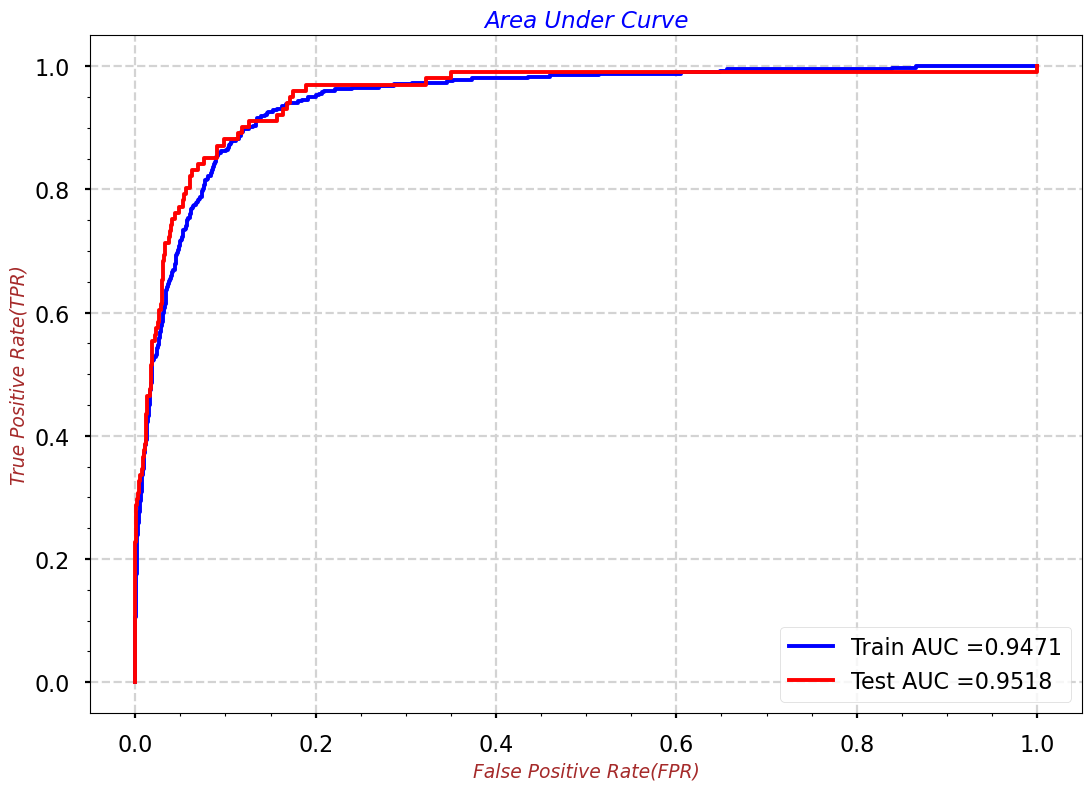

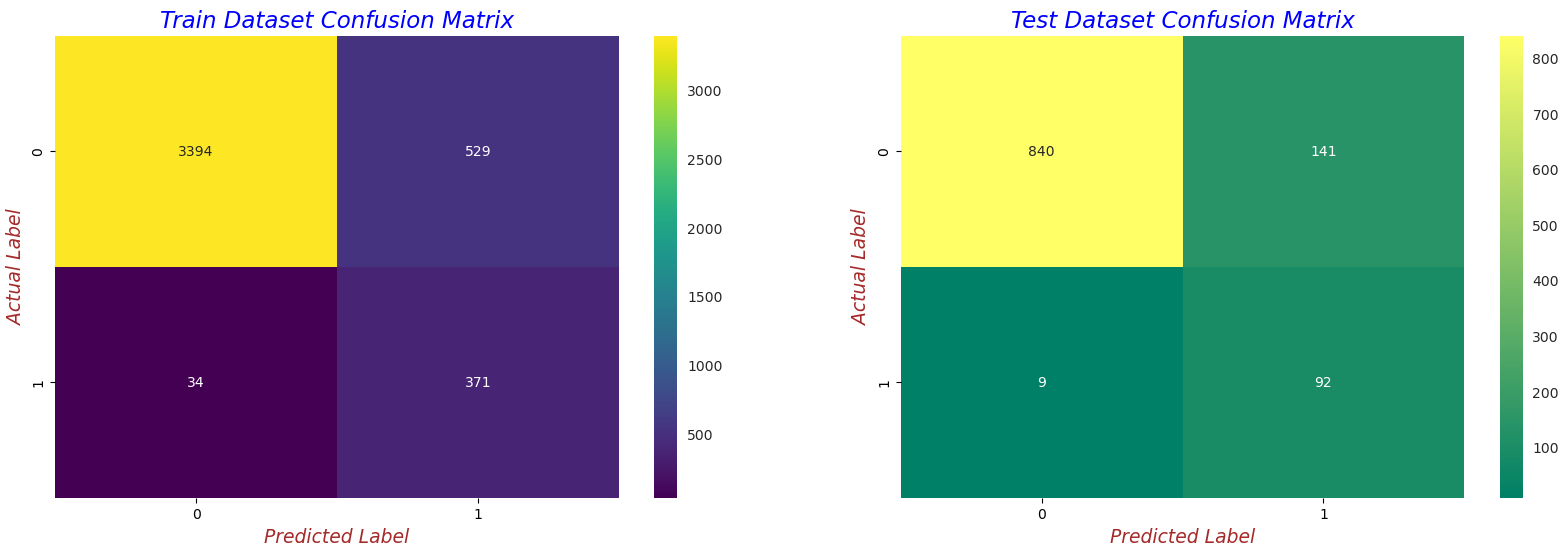



Best Threshold = 0.3544
Model AUC is : 0.9518
Model Train F1 Score is : 0.5686
Model Test F1 Score is : 0.5509
Classification Report is: 
               precision    recall  f1-score   support

           0       0.99      0.86      0.92       981
           1       0.39      0.91      0.55       101

    accuracy                           0.86      1082
   macro avg       0.69      0.88      0.73      1082
weighted avg       0.93      0.86      0.88      1082



In [17]:
# Validate Logistic Regression model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(lr, X_train_std, X_test_std, y_train, y_test)

print("\n")
lr_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr )

In [18]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': lr.coef_[0]})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,0.548121
1,Admitted_Duration,0.548848
2,PRV_Tot_DGrpCodes,-0.037874
3,PRV_Tot_Unq_DOB_Years,-0.270709
4,PRV_Bene_Age_Sum,0.054760


In [19]:
top_15_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:15]
top_15_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:15]

In [20]:
top_15_neg_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=True)['Features'].iloc[0:15]
top_15_neg_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=True)['Importance_Model_1'].iloc[0:15]

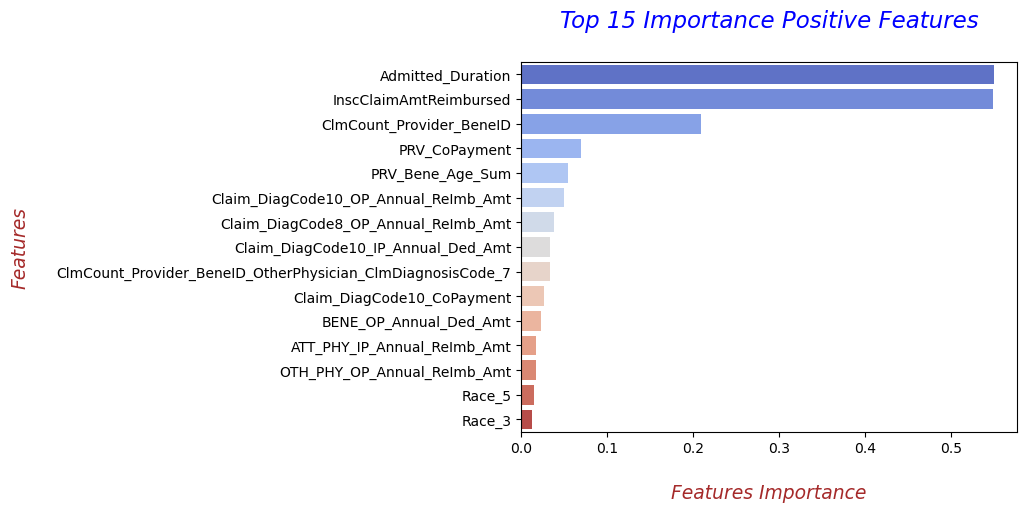

In [21]:
sns.barplot(y=top_15_pos_feats, x=top_15_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 15 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

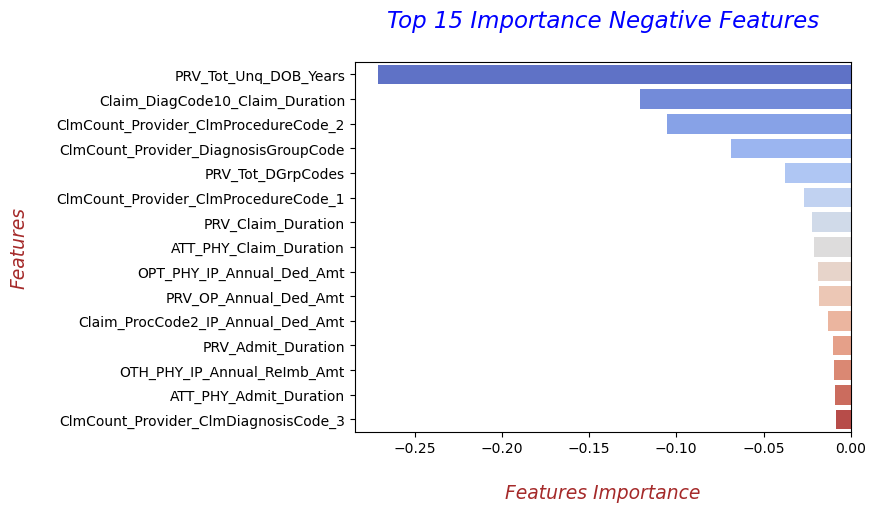

In [22]:
sns.barplot(y=top_15_neg_feats, x=top_15_neg_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 15 Importance Negative Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--`Decision Tree`-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [23]:
from sklearn.tree import DecisionTreeClassifier

In [24]:
# Training the model with all features and hyper-parameterized values
dt = DecisionTreeClassifier(criterion='gini',
                                   max_depth= 6,
                                   max_features='log2',
                                   min_samples_leaf=150,
                                   min_samples_split=150,
                                   class_weight='balanced',
                                   random_state=49,
                                   splitter='best',
                                   min_weight_fraction_leaf=0.0,
                                   max_leaf_nodes=None,
                                   min_impurity_decrease=0.0,
                                   ccp_alpha=0.0,)

dt.fit(X_train_std, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=6,
                       max_features='log2', min_samples_leaf=150,
                       min_samples_split=150, random_state=49)

Train AUC = 0.9264832595361951
Test AUC = 0.9259948930672883


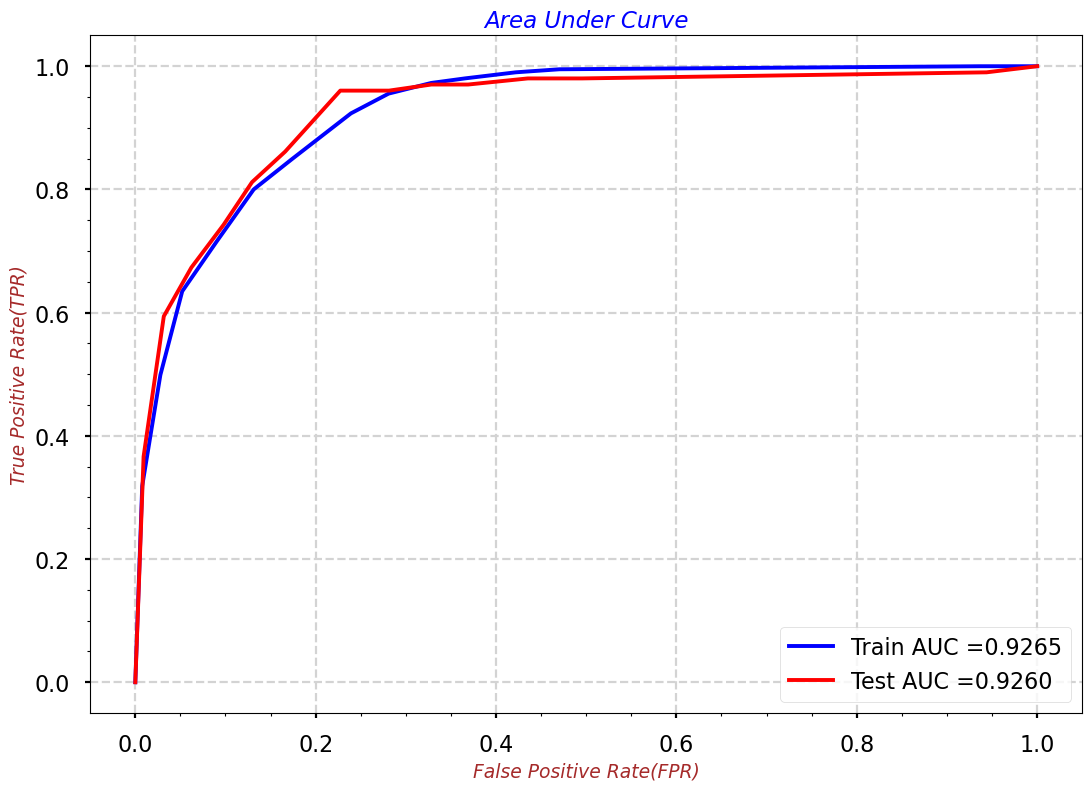

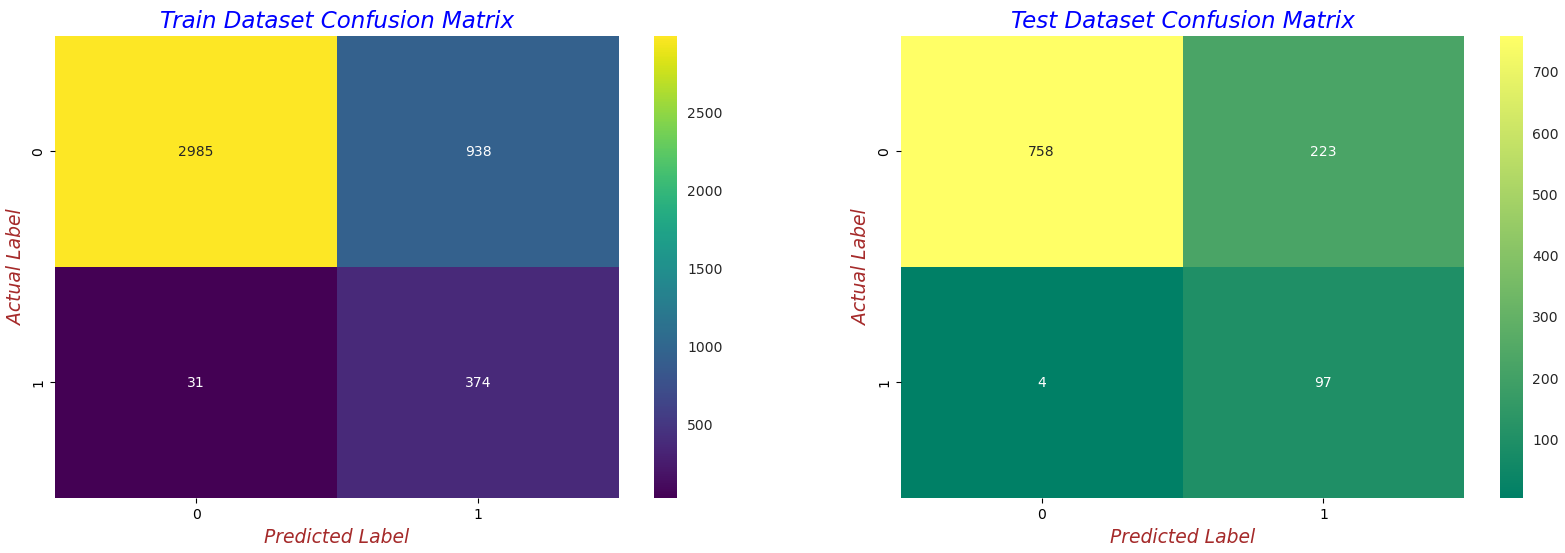



Best Threshold = 0.5316
Model AUC is : 0.9260
Model Train F1 Score is : 0.4356
Model Test F1 Score is : 0.4608
Classification Report is: 
               precision    recall  f1-score   support

           0       0.99      0.77      0.87       981
           1       0.30      0.96      0.46       101

    accuracy                           0.79      1082
   macro avg       0.65      0.87      0.67      1082
weighted avg       0.93      0.79      0.83      1082



In [25]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(dt, X_train_std, X_test_std, y_train, y_test)

print("\n")
dt_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr )

In [26]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': dt.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,DeductibleAmtPaid,0.040583
1,OPT_PHY_Admit_Duration,0.003299
2,OTH_PHY_Claim_Duration,0.000785
3,Claim_Admit_Diag_Code_IP_Annual_ReImb_Amt,0.700819
4,Claim_Admit_Diag_Code_IP_Annual_Ded_Amt,0.002466


In [27]:
top_15_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:15]
top_15_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:15]

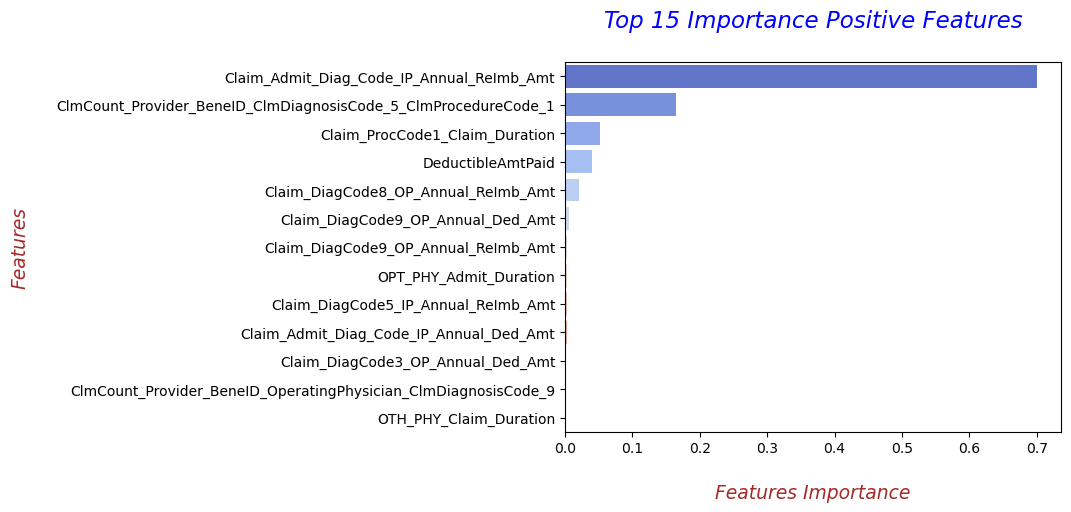

In [28]:
sns.barplot(y=top_15_pos_feats, x=top_15_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 15 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--`Random Forest Classifier`-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [30]:
# Training the model with all features and hyper-parameterized values
rf = RandomForestClassifier(n_estimators=30,criterion='gini',
                                   max_depth= 4,
                                   max_features='auto',
                                   min_samples_leaf=50,
                                   min_samples_split=50,
                                   class_weight='balanced',
                                   random_state=49,
                                   min_weight_fraction_leaf=0.0,
                                   max_leaf_nodes=None,
                                   min_impurity_decrease=0.0,
                                   ccp_alpha=0.0,)

rf.fit(X_train_std, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=4,
                       min_samples_leaf=50, min_samples_split=50,
                       n_estimators=30, random_state=49)

Train AUC = 0.9457812898292124
Test AUC = 0.9517970145638417


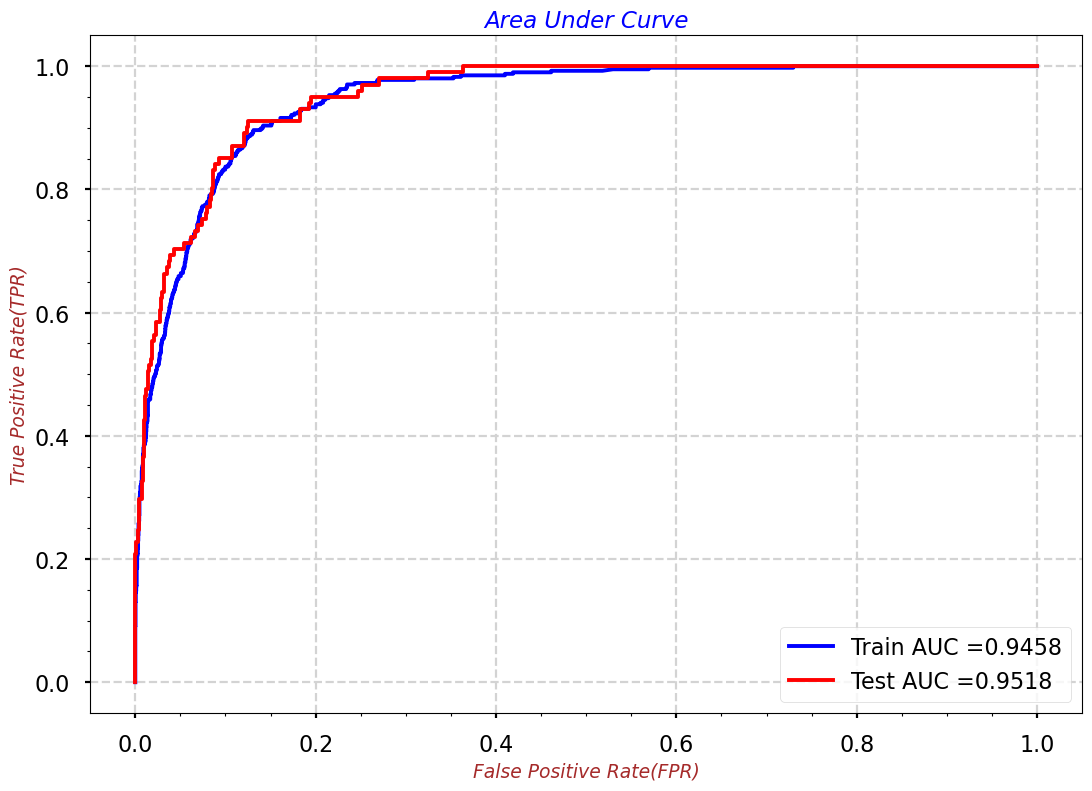

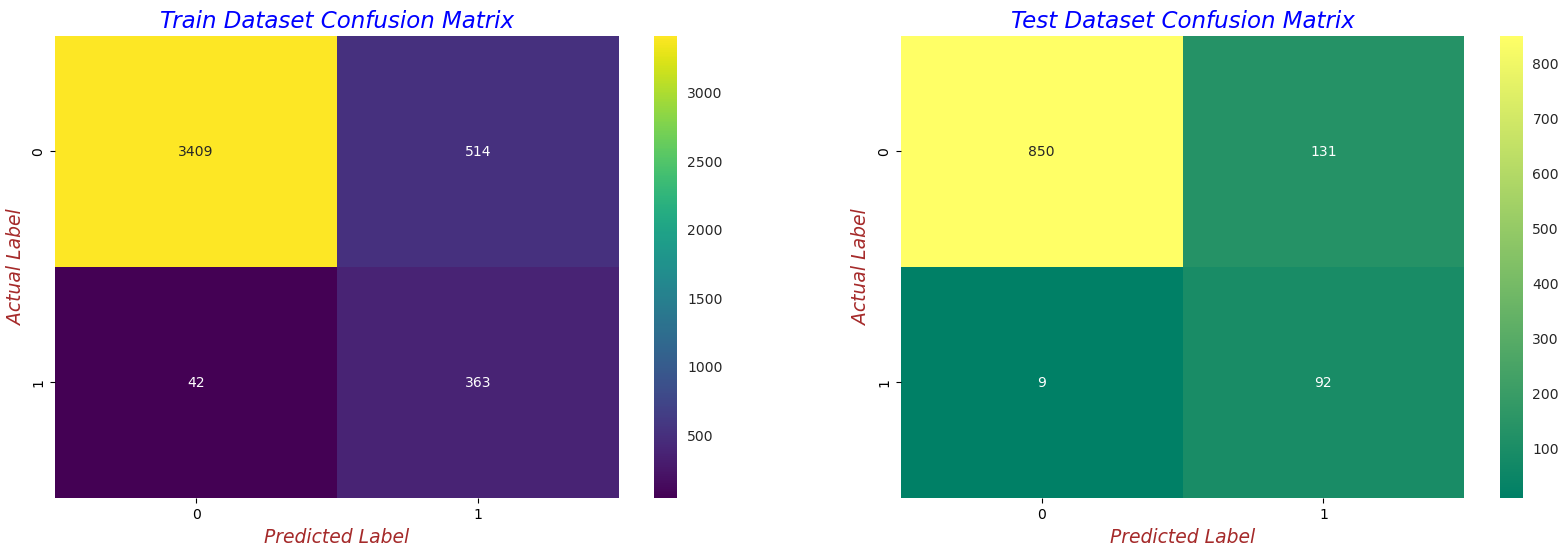



Best Threshold = 0.5390
Model AUC is : 0.9518
Model Train F1 Score is : 0.5663
Model Test F1 Score is : 0.5679
Classification Report is: 
               precision    recall  f1-score   support

           0       0.99      0.87      0.92       981
           1       0.41      0.91      0.57       101

    accuracy                           0.87      1082
   macro avg       0.70      0.89      0.75      1082
weighted avg       0.94      0.87      0.89      1082



In [31]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(rf, X_train_std, X_test_std, y_train, y_test)

print("\n")
rf_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr )

In [32]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': rf.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,0.012603
1,DeductibleAmtPaid,0.028761
2,RenalDiseaseIndicator,0.000322
3,ChronicCond_ObstrPulmonary,0.000937
4,ChronicCond_Diabetes,0.000268


In [33]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

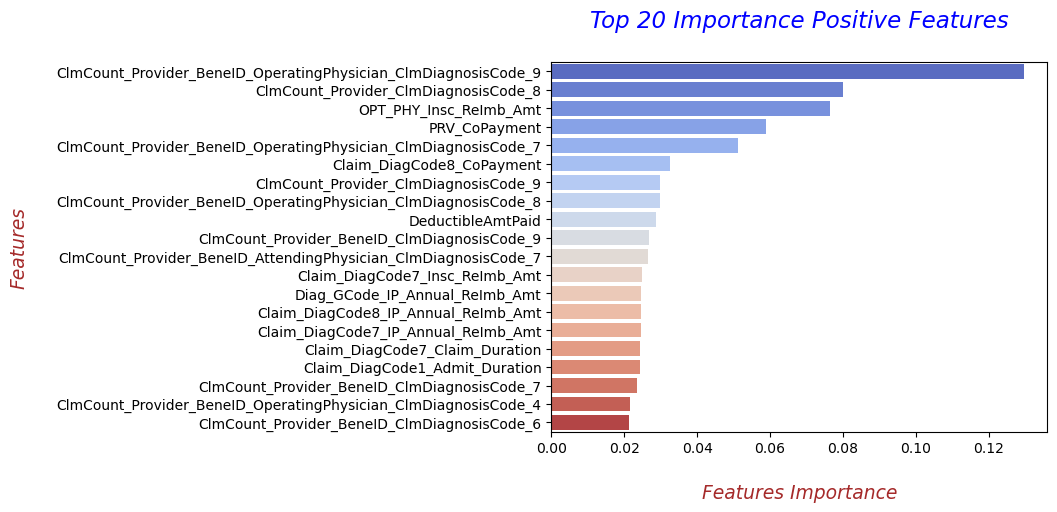

In [34]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Support Vector Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [35]:
from sklearn.svm import SVC

svc = SVC(probability=True)
svc.fit(X_train_std, y_train)


SVC(probability=True)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.8256297932736033
Test AUC = 0.8374461299340943


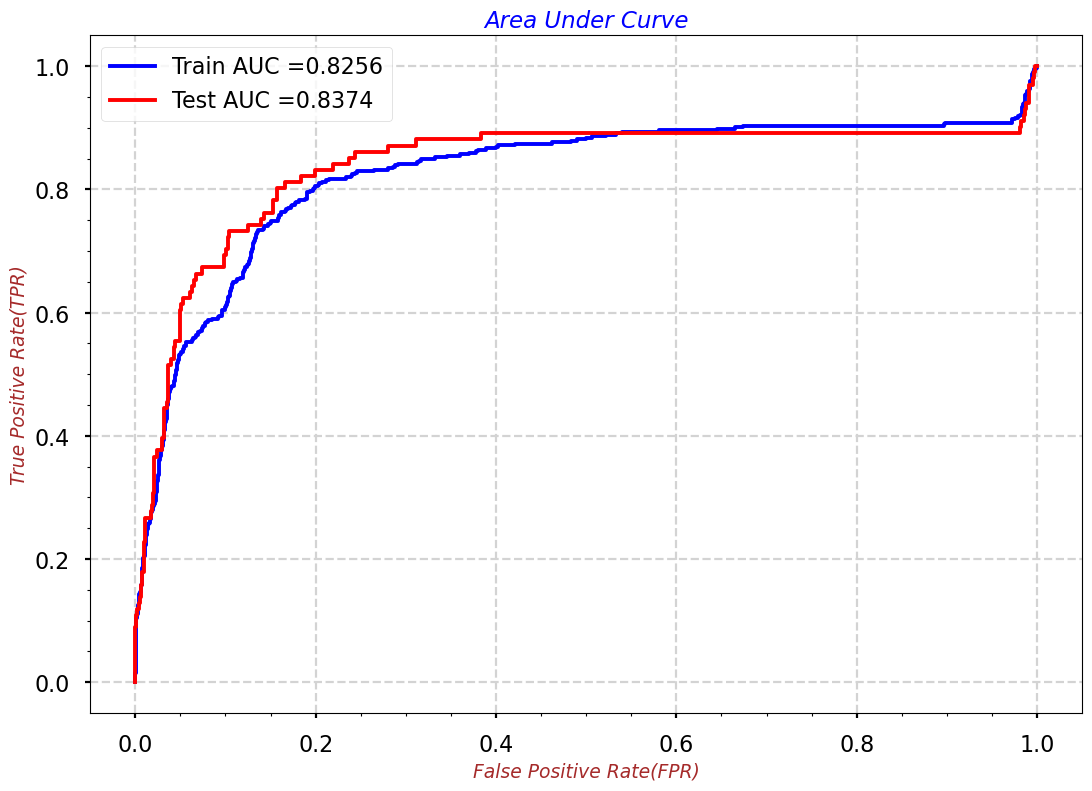

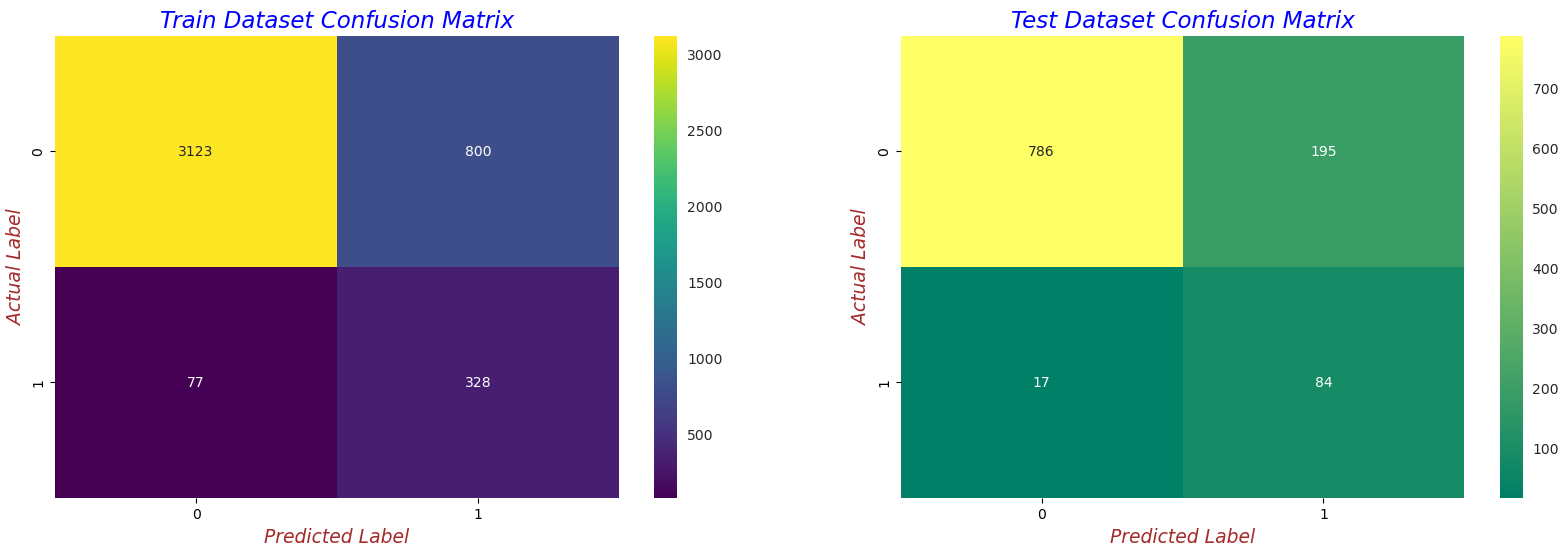



Best Threshold = 0.0771
Model AUC is : 0.8374
Model Train F1 Score is : 0.4279
Model Test F1 Score is : 0.4421
Classification Report is: 
               precision    recall  f1-score   support

           0       0.98      0.80      0.88       981
           1       0.30      0.83      0.44       101

    accuracy                           0.80      1082
   macro avg       0.64      0.82      0.66      1082
weighted avg       0.92      0.80      0.84      1082



In [36]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(svc, X_train_std, X_test_std, y_train, y_test)

print("\n")
svc_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Gradient Boosting Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [37]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier()
gb.fit(X_train_std, y_train)


GradientBoostingClassifier()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.9813600073010389
Test AUC = 0.9530586086131548


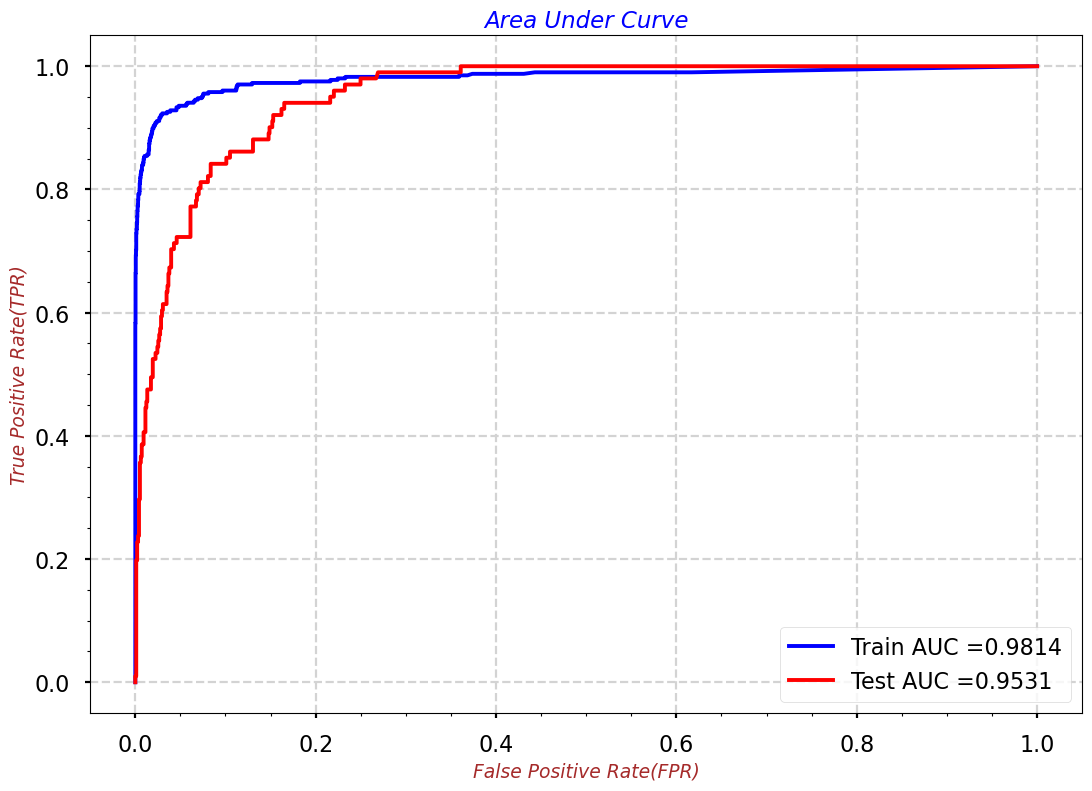

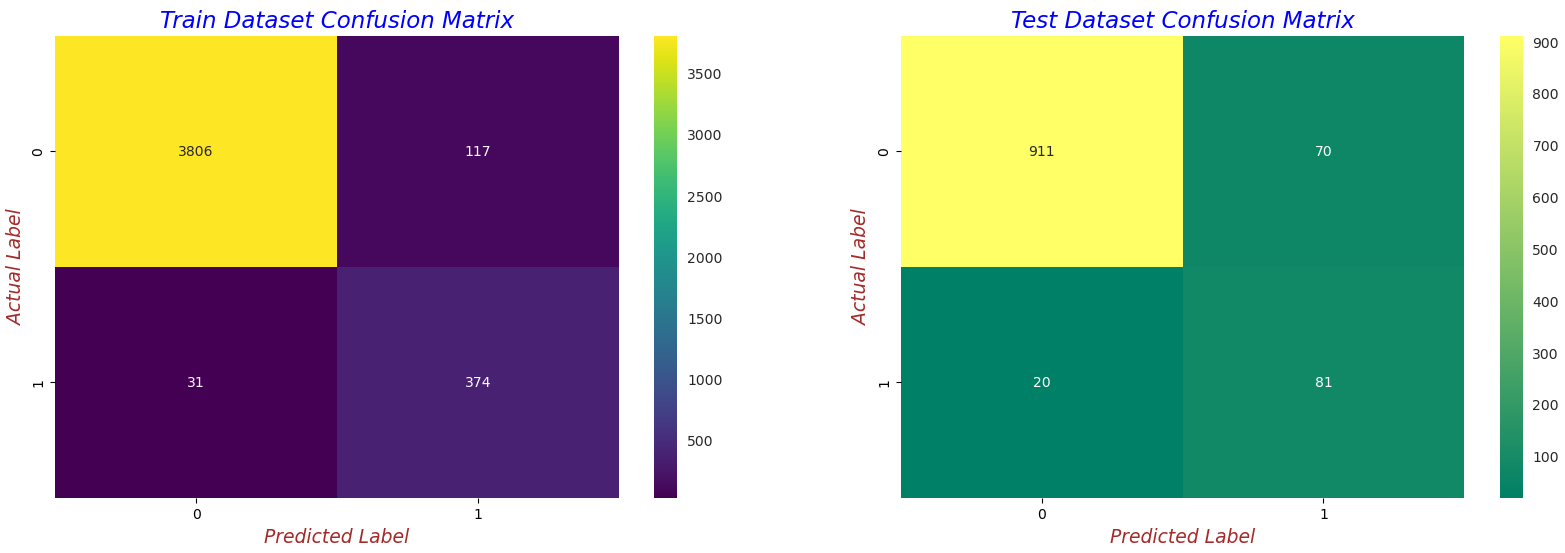



Best Threshold = 0.2433
Model AUC is : 0.9531
Model Train F1 Score is : 0.8348
Model Test F1 Score is : 0.6429
Classification Report is: 
               precision    recall  f1-score   support

           0       0.98      0.93      0.95       981
           1       0.54      0.80      0.64       101

    accuracy                           0.92      1082
   macro avg       0.76      0.87      0.80      1082
weighted avg       0.94      0.92      0.92      1082



In [38]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(gb, X_train_std, X_test_std, y_train, y_test)

print("\n")
gb_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [39]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': gb.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,0.463382
1,DeductibleAmtPaid,0.007136
2,RenalDiseaseIndicator,0.000814
3,ChronicCond_Cancer,0.000536
4,ChronicCond_IschemicHeart,0.000587


In [40]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

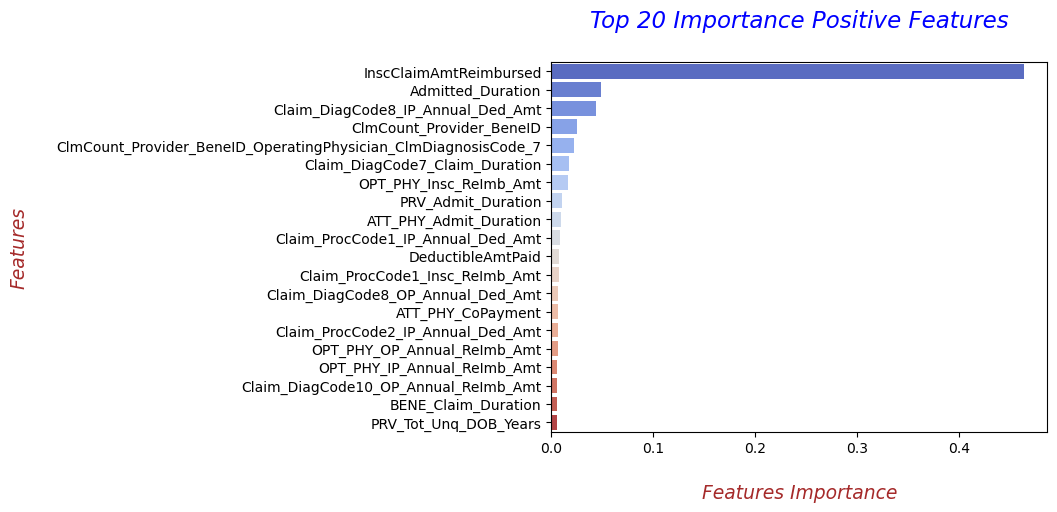

In [41]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Stochastic Gradient Boosting (SGB)-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [42]:
sgb = GradientBoostingClassifier(subsample = 0.90, max_features = 0.70)
sgb.fit(X_train_std, y_train)


GradientBoostingClassifier(max_features=0.7, subsample=0.9)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.9792697702375669
Test AUC = 0.9524227652123011


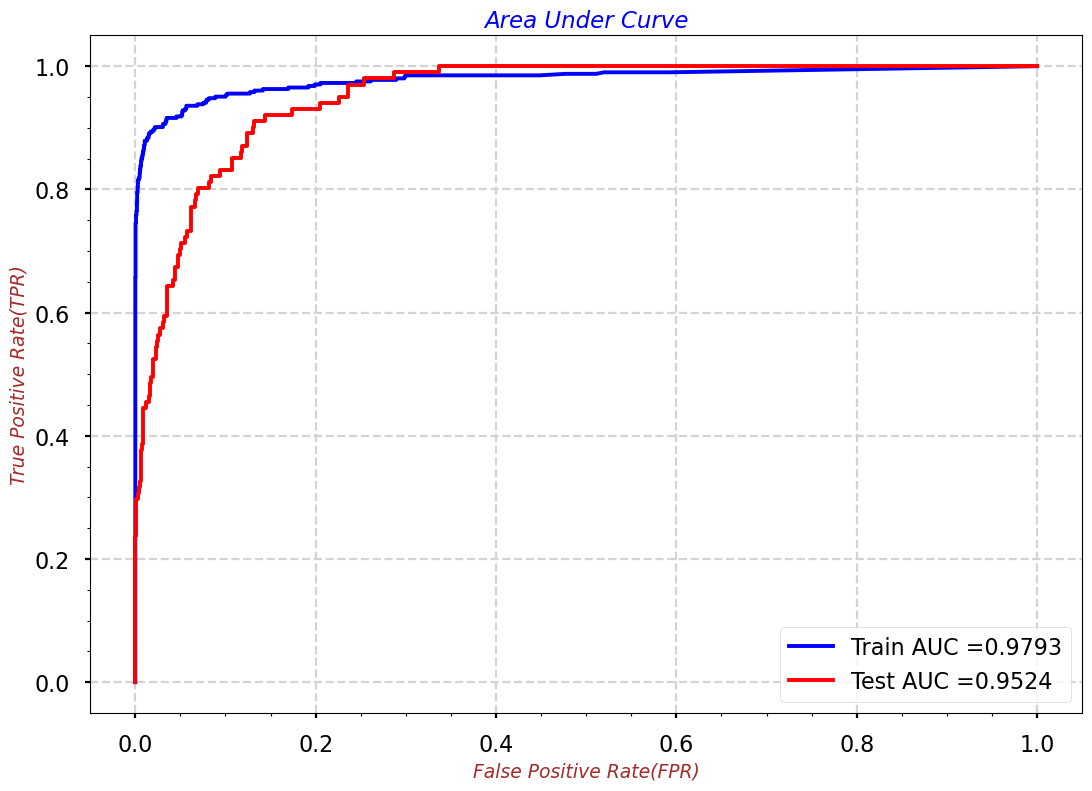

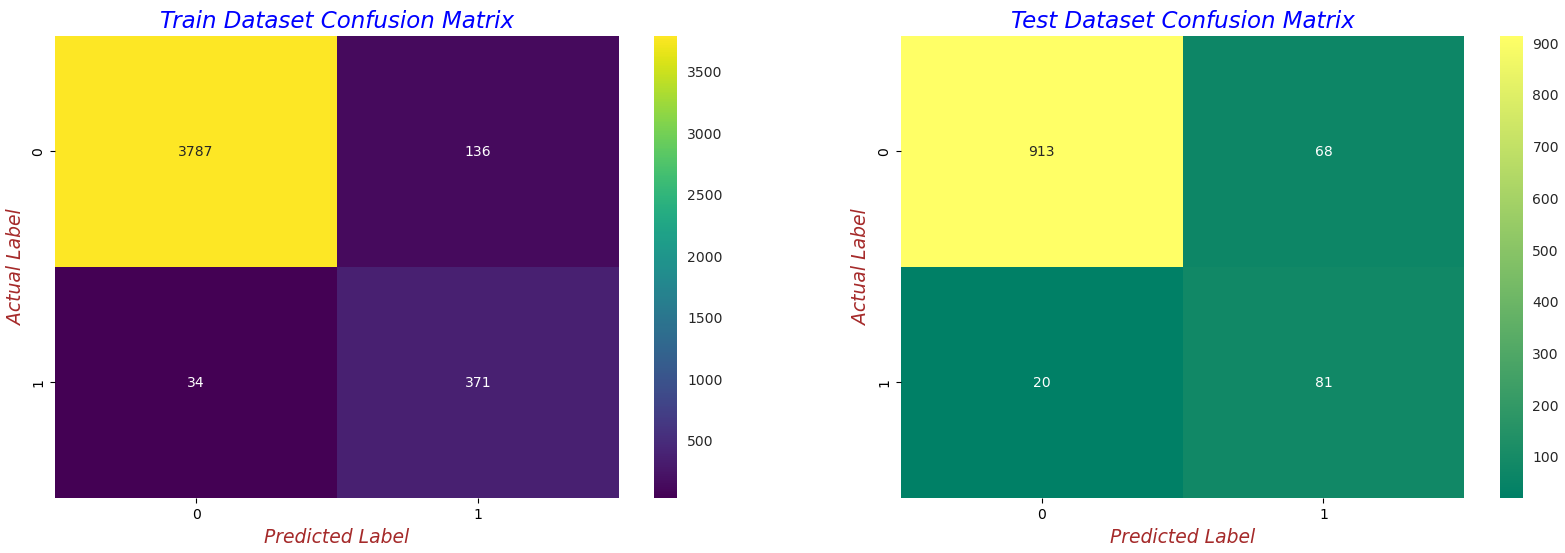



Best Threshold = 0.2338
Model AUC is : 0.9524
Model Train F1 Score is : 0.8136
Model Test F1 Score is : 0.6480
Classification Report is: 
               precision    recall  f1-score   support

           0       0.98      0.93      0.95       981
           1       0.54      0.80      0.65       101

    accuracy                           0.92      1082
   macro avg       0.76      0.87      0.80      1082
weighted avg       0.94      0.92      0.93      1082



In [43]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(sgb, X_train_std, X_test_std, y_train, y_test)

print("\n")
sgb_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [44]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': sgb.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,0.429578
1,DeductibleAmtPaid,0.003795
2,RenalDiseaseIndicator,0.000910
3,ChronicCond_Cancer,0.000028
4,ChronicCond_ObstrPulmonary,0.001619


In [45]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

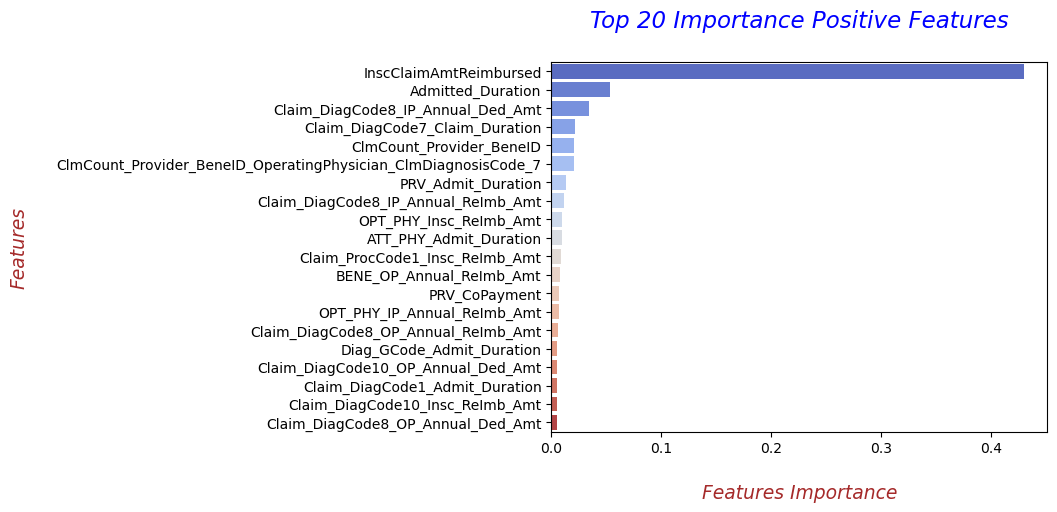

In [46]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--XgBoost Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [47]:
from xgboost import XGBClassifier

xgb = XGBClassifier()
xgb.fit(X_train_std, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              n_estimators=100, n_jobs=None, num_parallel_tree=None,
              predictor=None, random_state=None, ...)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 1.0
Test AUC = 0.9418859317124372


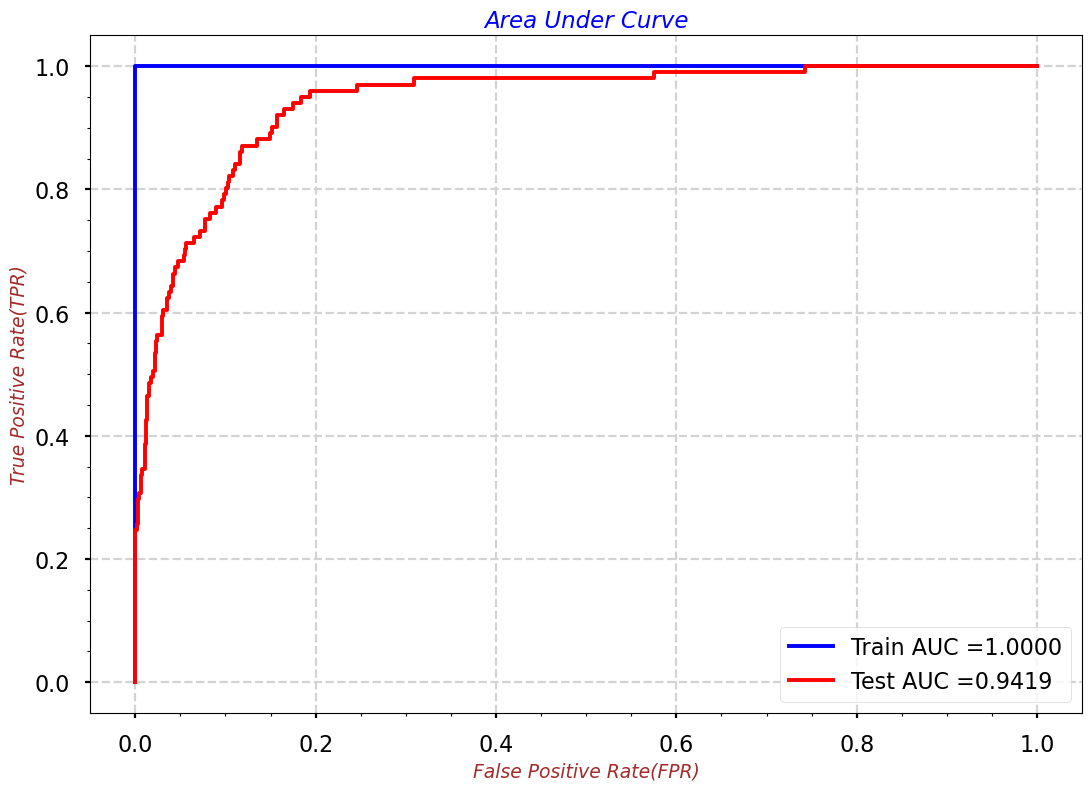

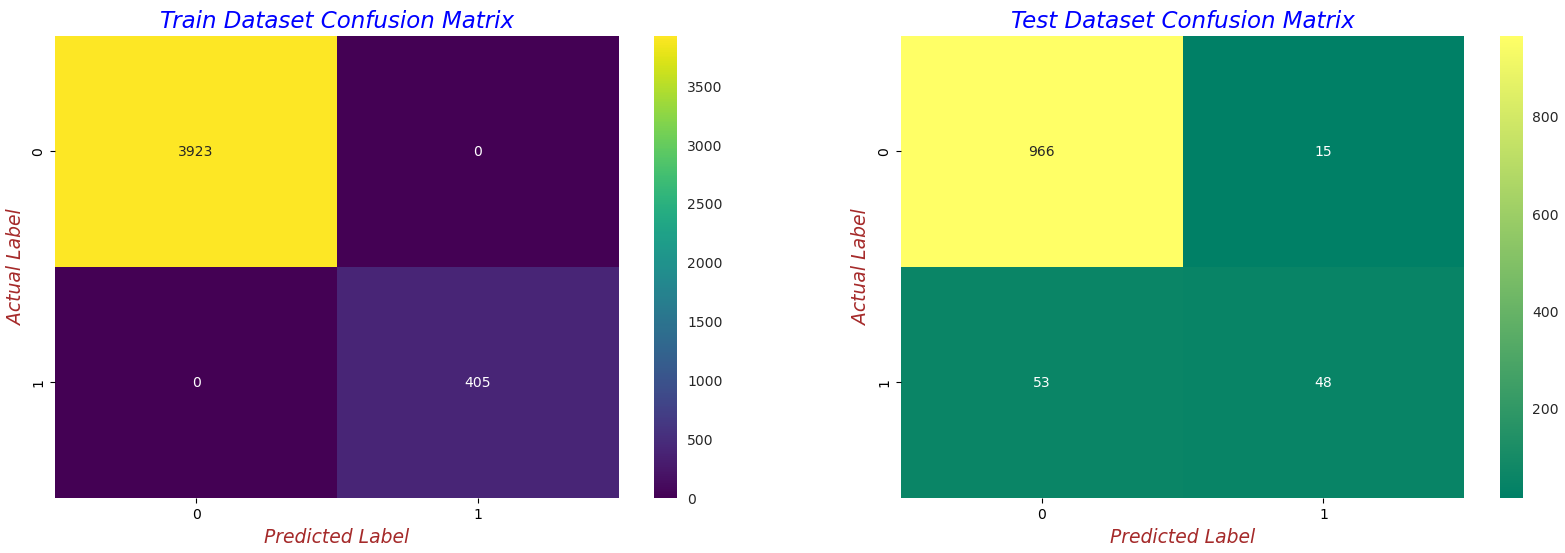



Best Threshold = 0.6826
Model AUC is : 0.9419
Model Train F1 Score is : 1.0000
Model Test F1 Score is : 0.5854
Classification Report is: 
               precision    recall  f1-score   support

           0       0.95      0.98      0.97       981
           1       0.76      0.48      0.59       101

    accuracy                           0.94      1082
   macro avg       0.85      0.73      0.78      1082
weighted avg       0.93      0.94      0.93      1082



In [48]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(xgb, X_train_std, X_test_std, y_train, y_test)

print("\n")
xgb_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [49]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': xgb.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.Features.head()

0       InscClaimAmtReimbursed
1            DeductibleAmtPaid
2        RenalDiseaseIndicator
3        ChronicCond_Alzheimer
4    ChronicCond_KidneyDisease
Name: Features, dtype: object

In [50]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

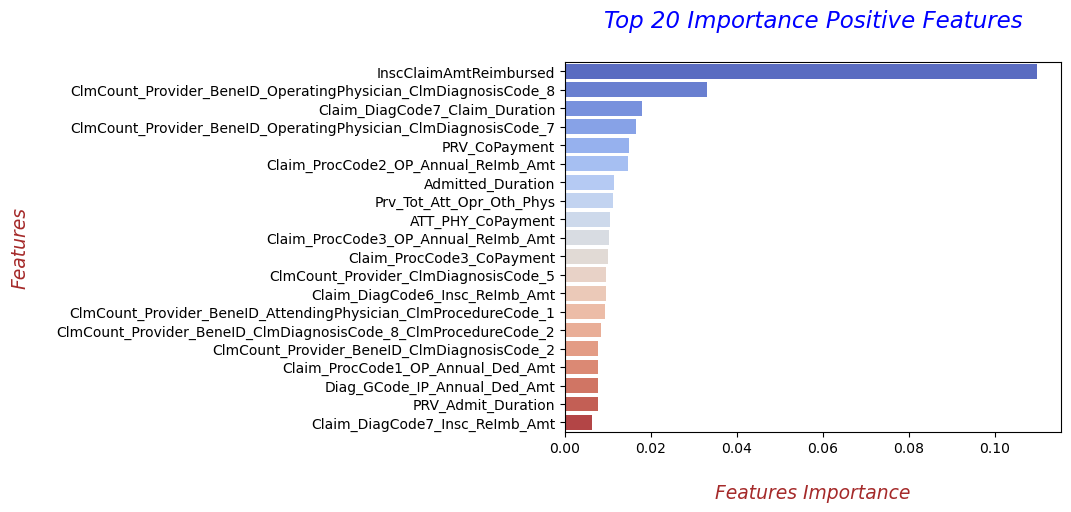

In [51]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Cat Boost Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [52]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(iterations=10)
cat.fit(X_train_std, y_train)

Learning rate set to 0.5
0:	learn: 0.2637822	total: 250ms	remaining: 2.25s
1:	learn: 0.1839306	total: 328ms	remaining: 1.31s
2:	learn: 0.1678157	total: 391ms	remaining: 912ms
3:	learn: 0.1626057	total: 451ms	remaining: 676ms
4:	learn: 0.1545124	total: 512ms	remaining: 512ms
5:	learn: 0.1487630	total: 569ms	remaining: 379ms
6:	learn: 0.1465288	total: 624ms	remaining: 267ms
7:	learn: 0.1414795	total: 678ms	remaining: 169ms
8:	learn: 0.1360438	total: 735ms	remaining: 81.7ms
9:	learn: 0.1308888	total: 793ms	remaining: 0us


**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.9556487067405582
Test AUC = 0.9405839666535462


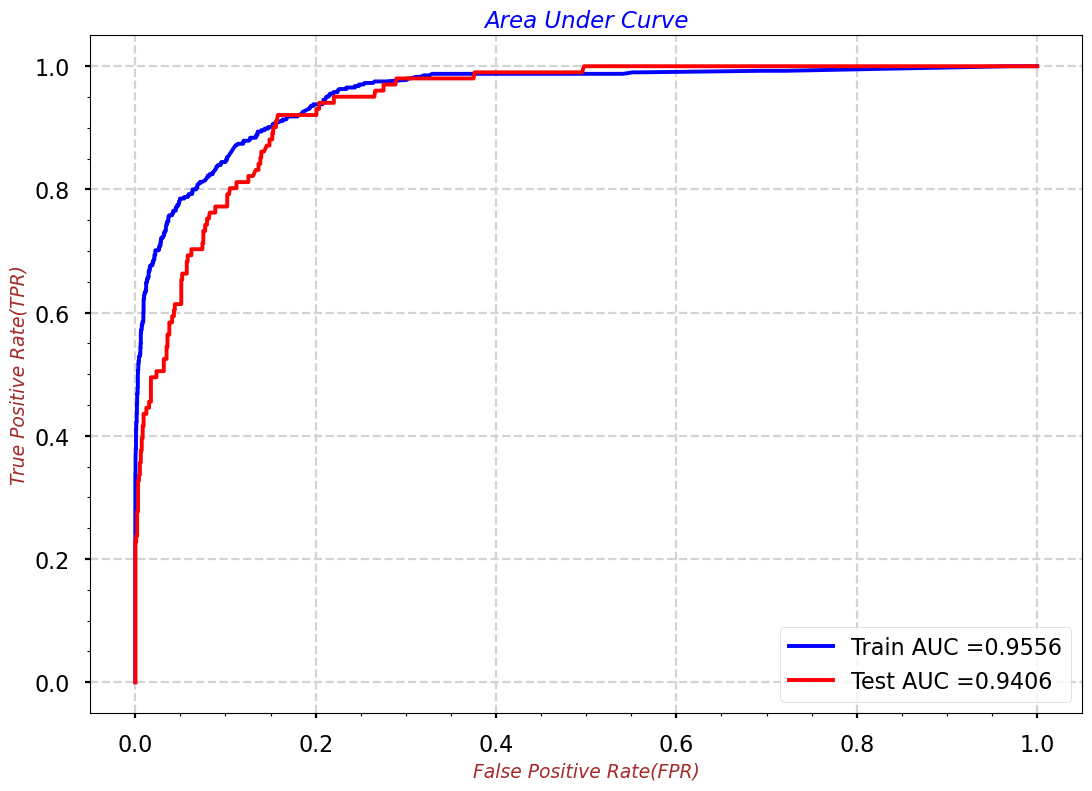

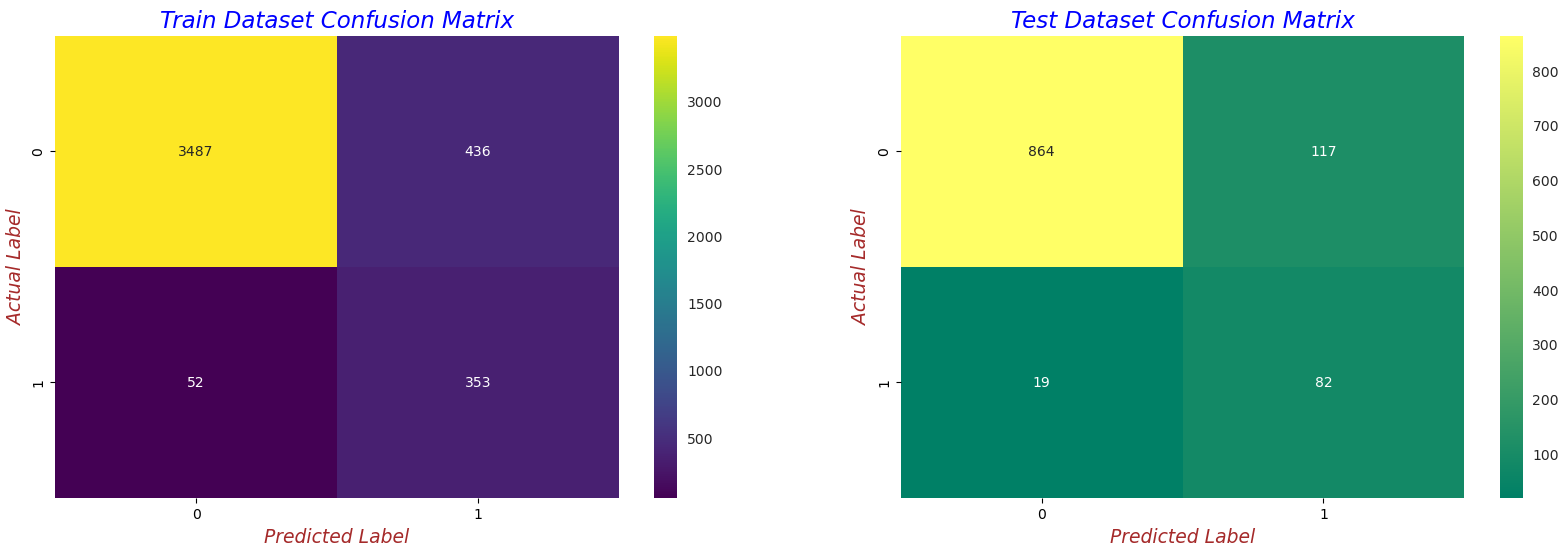



Best Threshold = 0.1311
Model AUC is : 0.9406
Model Train F1 Score is : 0.5913
Model Test F1 Score is : 0.5467
Classification Report is: 
               precision    recall  f1-score   support

           0       0.98      0.88      0.93       981
           1       0.41      0.81      0.55       101

    accuracy                           0.87      1082
   macro avg       0.70      0.85      0.74      1082
weighted avg       0.93      0.87      0.89      1082



In [53]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(cat, X_train_std, X_test_std, y_train, y_test)

print("\n")
cat_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [54]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': cat.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,DeductibleAmtPaid,7.921100
1,ChronicCond_stroke,0.241449
2,Admitted_Duration,5.635783
3,Bene_Age,0.774664
4,PRV_IP_Annual_Ded_Amt,0.505886


In [55]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

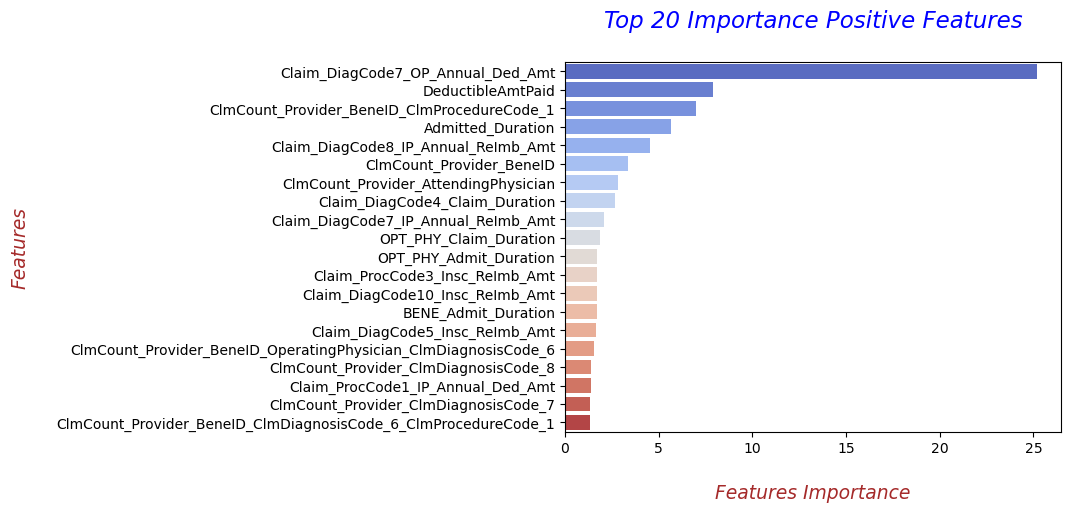

In [56]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Extra Trees Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [57]:
from sklearn.ensemble import ExtraTreesClassifier

etc = ExtraTreesClassifier()
etc.fit(X_train_std, y_train)

ExtraTreesClassifier()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 1.0
Test AUC = 0.9414822216166571


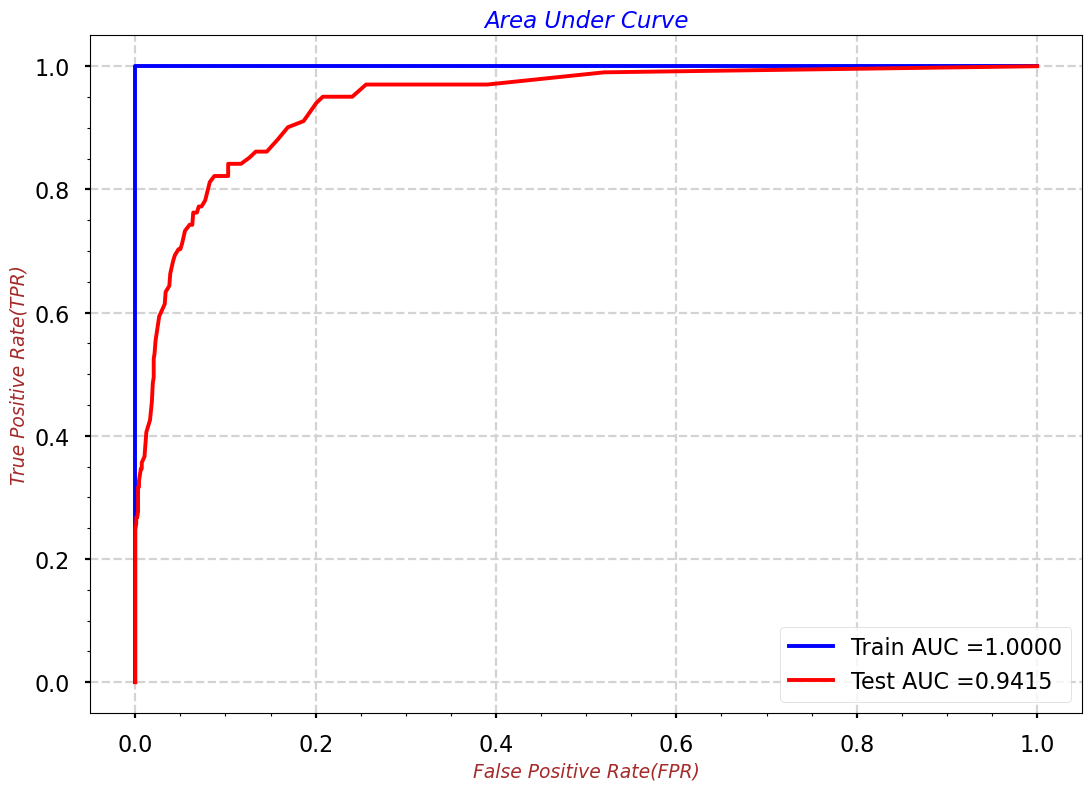

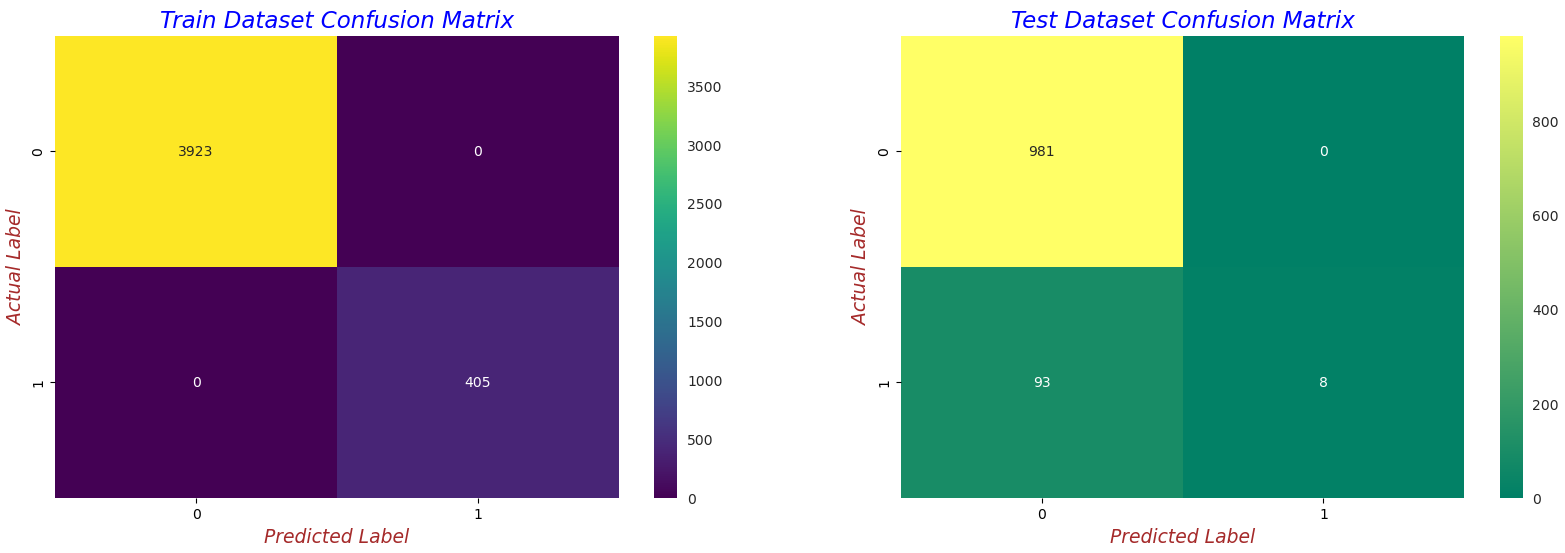



Best Threshold = 1.0000
Model AUC is : 0.9415
Model Train F1 Score is : 1.0000
Model Test F1 Score is : 0.1468
Classification Report is: 
               precision    recall  f1-score   support

           0       0.91      1.00      0.95       981
           1       1.00      0.08      0.15       101

    accuracy                           0.91      1082
   macro avg       0.96      0.54      0.55      1082
weighted avg       0.92      0.91      0.88      1082



In [58]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(etc, X_train_std, X_test_std, y_train, y_test)

print("\n")
etc_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [59]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': etc.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,0.009593
1,DeductibleAmtPaid,0.006871
2,RenalDiseaseIndicator,0.002039
3,ChronicCond_Alzheimer,0.001780
4,ChronicCond_Heartfailure,0.003275


In [60]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

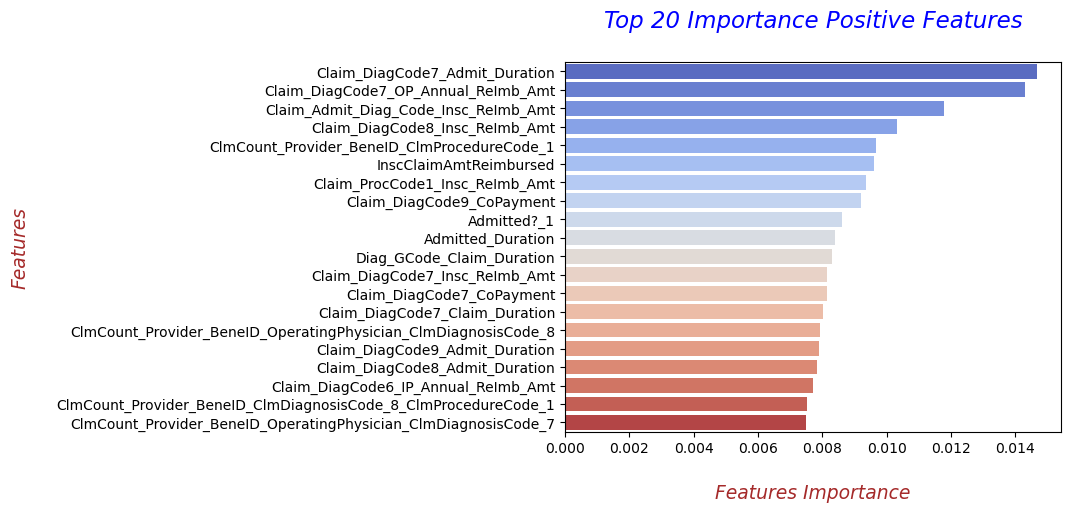

In [61]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--LGBM Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [62]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(learning_rate = 1)
lgbm.fit(X_train_std, y_train)

[LightGBM] [Info] Number of positive: 405, number of negative: 3923
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.022656 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 56832
[LightGBM] [Info] Number of data points in the train set: 4328, number of used features: 299
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.093577 -> initscore=-2.270725
[LightGBM] [Info] Start training from score -2.270725
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are

LGBMClassifier(learning_rate=1)

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.621090875904369
Test AUC = 0.5868329952261281


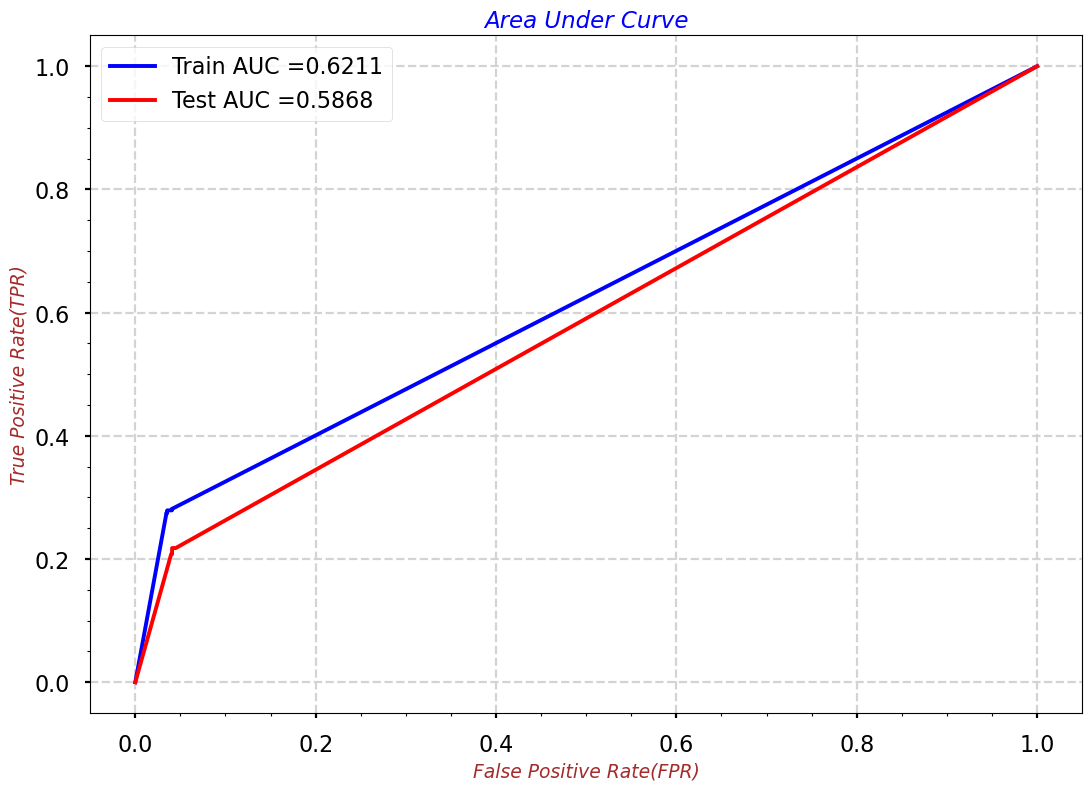

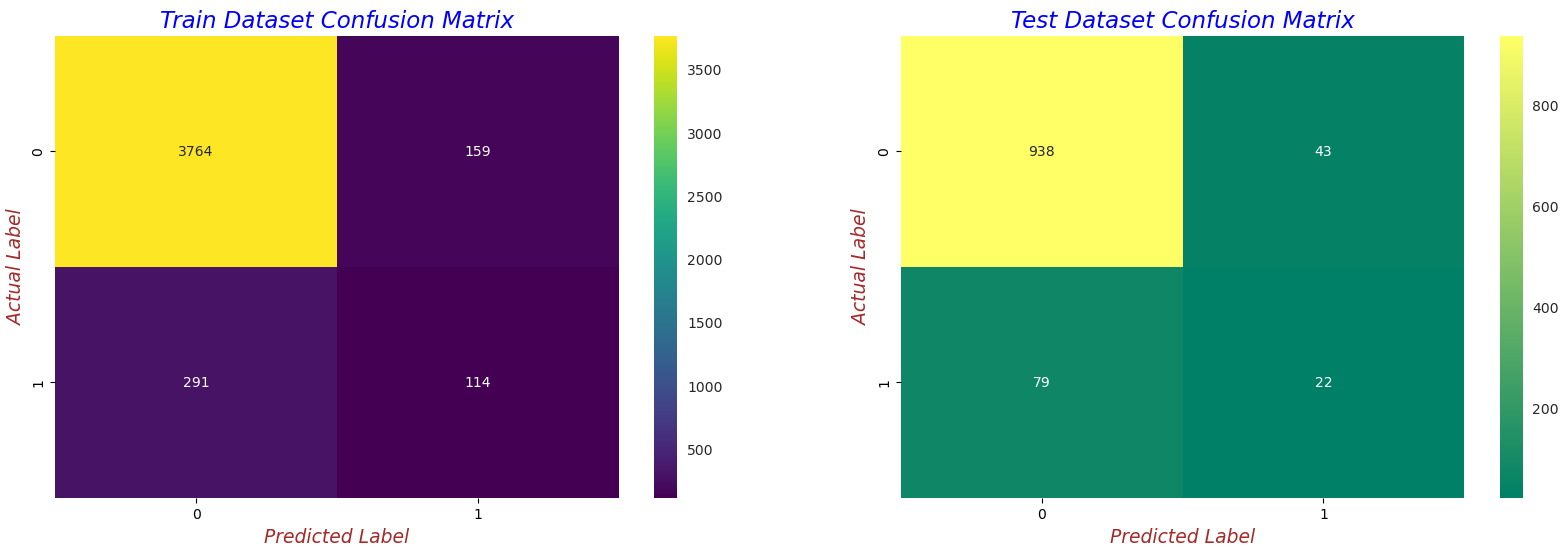



Best Threshold = 0.0000
Model AUC is : 0.5868
Model Train F1 Score is : 0.3363
Model Test F1 Score is : 0.2651
Classification Report is: 
               precision    recall  f1-score   support

           0       0.92      0.96      0.94       981
           1       0.34      0.22      0.27       101

    accuracy                           0.89      1082
   macro avg       0.63      0.59      0.60      1082
weighted avg       0.87      0.89      0.88      1082



In [63]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(lgbm, X_train_std, X_test_std, y_train, y_test)

print("\n")
lgbm_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [64]:
feats_imps = pd.DataFrame({'Features': X_train.columns, 'Importance_Model_1': lgbm.feature_importances_})
feats_imps = feats_imps[feats_imps['Importance_Model_1'] != 0]
feats_imps.reset_index(drop=True, inplace=True)
feats_imps.head()

,Features,Importance_Model_1
0,InscClaimAmtReimbursed,23
1,DeductibleAmtPaid,4
2,RenalDiseaseIndicator,9
3,ChronicCond_Alzheimer,6
4,ChronicCond_Heartfailure,2


In [65]:
top_20_pos_feats = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Features'].iloc[0:20]
top_20_pos_feats_scores = feats_imps.sort_values(by='Importance_Model_1',axis=0,ascending=False)['Importance_Model_1'].iloc[0:20]

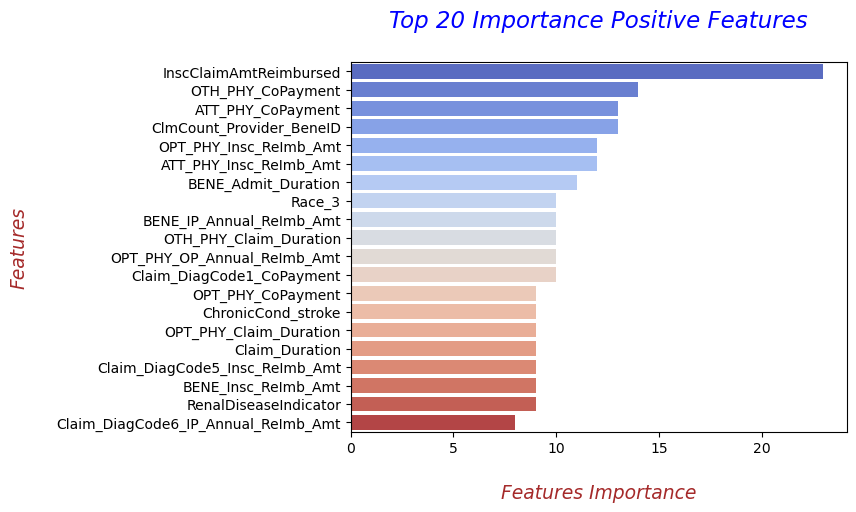

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

...

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed by the remote host
Exception in callback BaseSelectorEventLoop._read_from_self()
handle: <Handle BaseSelectorEventLoop._read_from_self()>
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\asyncio\events.py", line 80, in _run
    self._context.run(self._callback, *self._args)
  File "C:\ProgramData\Anaconda3\lib\asyncio\selector_events.py", line 115, in _read_from_self
    data = self._ssock.recv(4096)
ConnectionResetError: [WinError 10054] An existing connection was forcibly closed b

In [79]:
sns.barplot(y=top_20_pos_feats, x=top_20_pos_feats_scores, orient='h', palette='coolwarm')
plt.xlabel("\nFeatures Importance", fontdict=label_font_dict)
plt.ylabel("Features\n", fontdict=label_font_dict)
plt.title("Top 20 Importance Positive Features\n", fontdict=title_font_dict)
plt.show()

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Voting Classifier-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

In [67]:
from sklearn.ensemble import VotingClassifier

classifiers = [('Support Vector Classifier', svc),  ('Decision Tree', dt), ('Random Forest', rf),
                ('XGboost', xgb), ('Gradient Boosting Classifier', gb), ('SGB', sgb),
               ('Cat Boost', cat), ('Extra Trees Classifier', etc), ('LGBM', lgbm)]

vc = VotingClassifier(estimators = classifiers,voting='soft')
vc.fit(X_train_std, y_train)


Learning rate set to 0.5
0:	learn: 0.2637822	total: 72.6ms	remaining: 653ms
1:	learn: 0.1839306	total: 133ms	remaining: 531ms
2:	learn: 0.1678157	total: 194ms	remaining: 452ms
3:	learn: 0.1626057	total: 259ms	remaining: 389ms
4:	learn: 0.1545124	total: 328ms	remaining: 328ms
5:	learn: 0.1487630	total: 424ms	remaining: 283ms
6:	learn: 0.1465288	total: 487ms	remaining: 209ms
7:	learn: 0.1414795	total: 545ms	remaining: 136ms
8:	learn: 0.1360438	total: 602ms	remaining: 66.8ms
9:	learn: 0.1308888	total: 655ms	remaining: 0us
[LightGBM] [Info] Number of positive: 405, number of negative: 3923
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.027901 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 56832
[LightGBM] [Info] Number of data points in the train set: 4328, number of used features: 299
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.093577 -> initscore=-2.270725
[LightGBM] [Info] Start training f

VotingClassifier(estimators=[('Support Vector Classifier',
                              SVC(probability=True)),
                             ('Decision Tree',
                              DecisionTreeClassifier(class_weight='balanced',
                                                     max_depth=6,
                                                     max_features='log2',
                                                     min_samples_leaf=150,
                                                     min_samples_split=150,
                                                     random_state=49)),
                             ('Random Forest',
                              RandomForestClassifier(class_weight='balanced',
                                                     max_depth=4,
                                                     min_samples_leaf=50,
                                                     min_samples_split=50...
                                            num_parallel_

**-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--Accuracy_score, confusion_matrix and classification_report-*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--*--**

Train AUC = 0.9968385243089977
Test AUC = 0.949667443808601


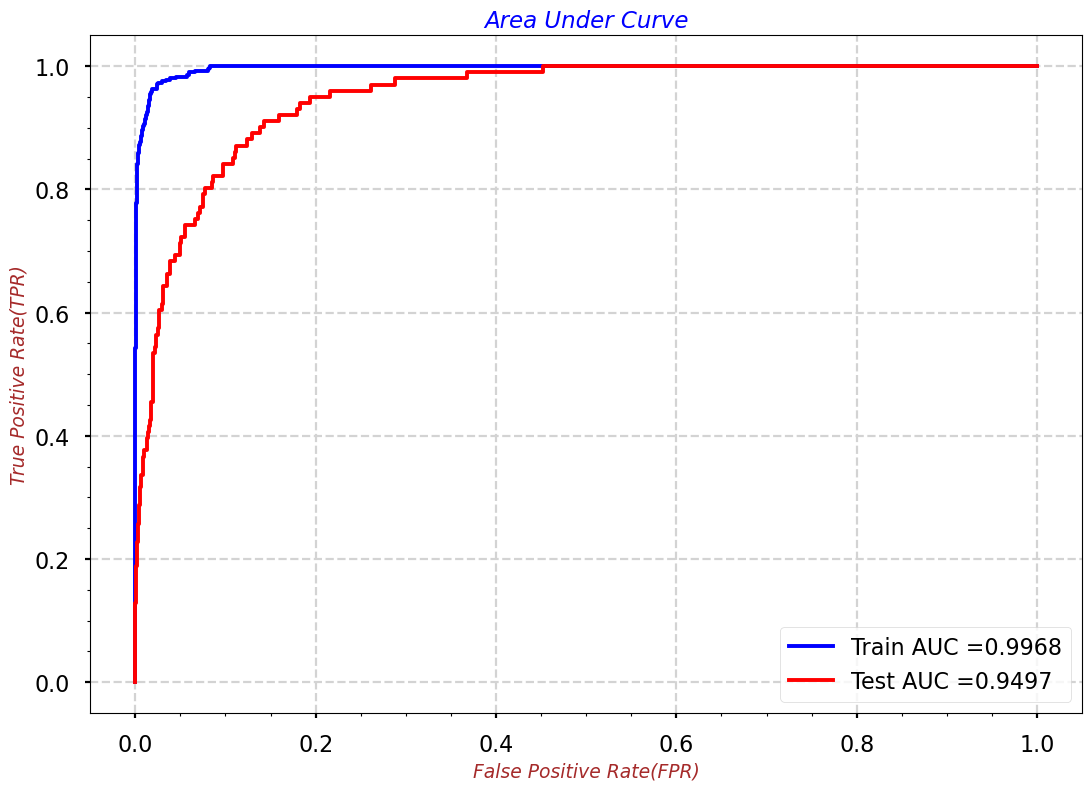

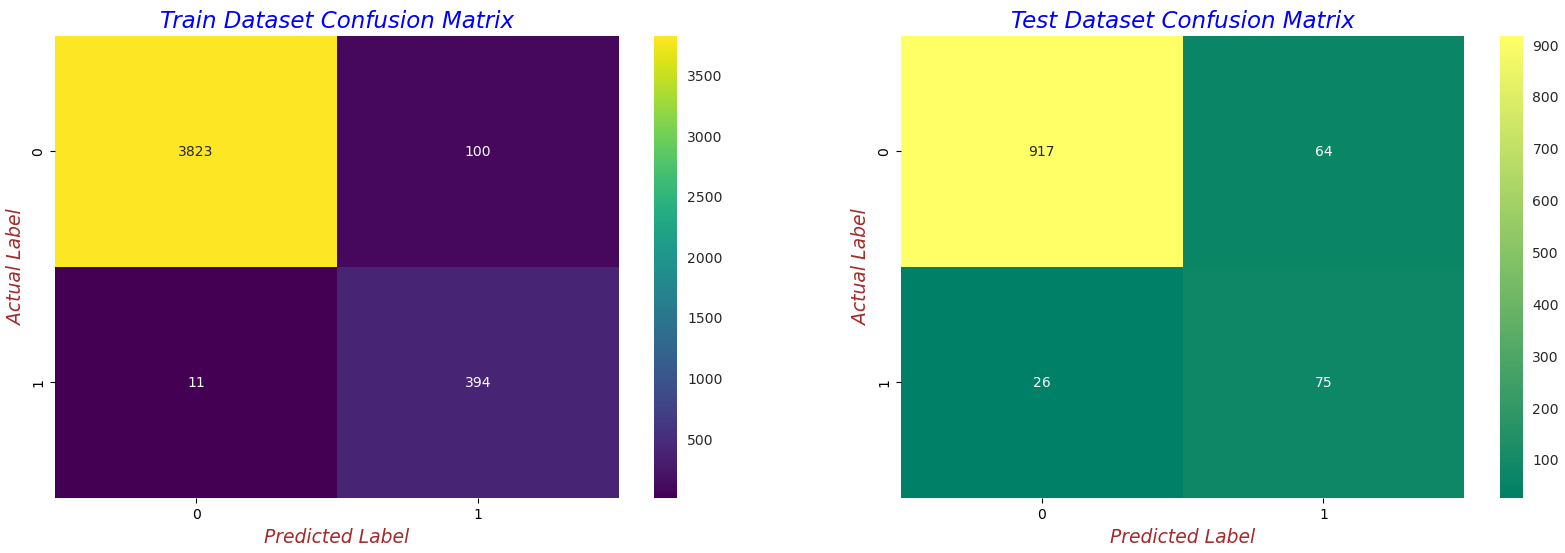



Best Threshold = 0.3386
Model AUC is : 0.9497
Model Train F1 Score is : 0.8765
Model Test F1 Score is : 0.6250
Classification Report is: 
               precision    recall  f1-score   support

           0       0.97      0.93      0.95       981
           1       0.54      0.74      0.62       101

    accuracy                           0.92      1082
   macro avg       0.76      0.84      0.79      1082
weighted avg       0.93      0.92      0.92      1082



In [68]:
# Validate model
test_auc, train_f1_score, test_f1_score, best_t,cr,acc_scr = validate_model(vc, X_train_std, X_test_std, y_train, y_test)

print("\n")
vc_acc = acc_scr
print("Best Threshold = {:.4f}".format(best_t))
print("Model AUC is : {:.4f}".format(test_auc))
print("Model Train F1 Score is : {:.4f}".format(train_f1_score))
print("Model Test F1 Score is : {:.4f}".format(test_f1_score))
print("Classification Report is: \n", cr)

In [69]:
models = pd.DataFrame({
    'Model' : ['SVC', 'Decision Tree', 'Random Forest', 'Gradient Boost', 'SGB', 'Cat Boost', 'Extra Trees', 'LGBM', 'XgBoost', 'Voting Classifier'],
    'Score' : [svc_acc, dt_acc, rf_acc,  gb_acc, sgb_acc, cat_acc, etc_acc, lgbm_acc, xgb_acc, vc_acc]
})


models.sort_values(by = 'Score', ascending = False)


,Model,Score
8,XgBoost,0.937153
4,SGB,0.918669
3,Gradient Boost,0.916821
9,Voting Classifier,0.916821
6,Extra Trees,0.914048
7,LGBM,0.887246
5,Cat Boost,0.874307
2,Random Forest,0.870610
0,SVC,0.804067
1,Decision Tree,0.790203


In [78]:
models = models.sort_values(by = 'Score', ascending = True)
px.bar(data_frame = models, x = 'Score', y = 'Model', color = 'Score', template = 'plotly_dark', 
       title = 'Models Comparison', )
